# Phase 3: Exploratory Data Analysis (EDA)

**What:** Look at the data with charts and tables to find patterns in readmissions.

**Why:** I need to understand the data before any modelling. EDA shows problems like class imbalance and features that are strongly linked.

## Setup

**What:** Import the libraries and set the file paths.

**Why:** Keeping them at the top makes them easy to change.

In [13]:
import numpy as np # numbers and np.select
import pandas as pd # tables
import matplotlib.pyplot as plt # charts
import seaborn as sns # nice charts

ENRICHED = '../data/processed/02_enriched.csv'   # Phase 2 output
ID_MAPPING = '../data/raw/IDs_mapping.csv'       # ID names file

sns.set_theme(style='whitegrid') # clean chart style

## Loading the Data and Making the Target

**What:** Load `02_enriched.csv` and make a new column `readmit_30` (1 = readmitted within 30 days, 0 = not).

**Why:** With 0 and 1, the average of `readmit_30` is the readmission rate. I use this rate for every comparison. `keep_default_na=False` keeps `'None'` as a real value.

In [16]:
# Keep text 'None', treat empty cells as NaN
df = pd.read_csv(ENRICHED, keep_default_na=False, na_values=[''], low_memory=False)
print(df.shape)

# Target: 1 if readmitted within 30 days, else 0
df['readmit_30'] = (df['readmitted'] == '<30').astype(int)

(100114, 50)


## Adding Names to the ID Columns

**What:** Add `admission_type` and `admission_source` name columns using `IDs_mapping.csv`.

**Why:** The brief (spec 3.3) asks for names on the ID columns, because numbers like 1 or 7 mean nothing. The discharge names are added later in section 4.4.

In [19]:
def load_mapping(table_name):
    """Read one table (e.g. 'admission_type_id') from IDs_mapping.csv."""
    mapping, in_table = {}, False
    with open(ID_MAPPING, encoding='utf-8-sig') as file:
        for line in file:
            code, _, description = line.strip().partition(',')
            if code == table_name: # header of the table we want
                in_table = True
            elif code.endswith('_id'): # header of another table
                in_table = False
            elif in_table and code.isdigit(): # a row of our table
                mapping[int(code)] = description.strip().strip('"')
    return mapping


# Add readable names for the two ID columns not yet mapped (spec 3.3)
for id_col, name_col in [('admission_type_id', 'admission_type'),
                         ('admission_source_id', 'admission_source')]:
    df[name_col] = df[id_col].map(load_mapping(id_col))

df[['admission_type', 'admission_source']].isna().mean()   # any unmapped IDs?

admission_type      0.0
admission_source    0.0
dtype: float64

## 1. Readmission Outcomes

**What:** Count plot of `readmitted` (NO, >30, <30), with the % of each.

**Why:** Hospitals are penalised for the `<30` group (HRRP). I need to know how small it is, because that changes how I compare results.

readmitted
NO     53.2
>30    35.5
<30    11.3
Name: proportion, dtype: float64


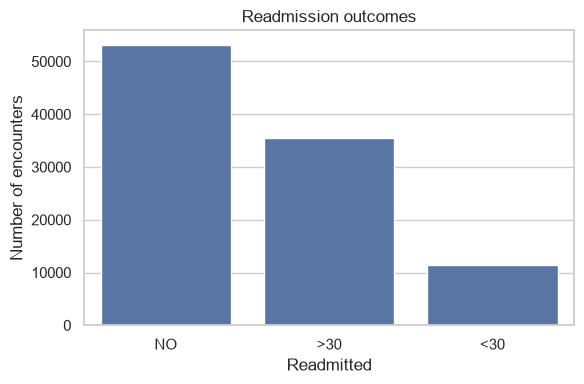

In [22]:
# Perecentage of each outcome
print(df['readmitted'].value_counts(normalize=True).mul(100).round(1))

# Count plot in a fixed order
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='readmitted', order=['NO', '>30', '<30'])
plt.title('Readmission outcomes')
plt.xlabel('Readmitted')
plt.ylabel('Number of encounters')
plt.tight_layout()
plt.show()